# Python para finanças - Taxas de Retorno Simples e Logarítmica

## Importação das bibliotecas e base de dados

In [6]:
import pandas as pd
import numpy as np
import plotly.express as px  ### para gerar gráficos dinâmicos ###

In [7]:
dataset = pd.read_csv('acoes_ex.csv')

In [8]:
dataset.shape

(1446, 7)

In [9]:
dataset.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66


In [10]:
dataset['Date'] = pd.to_datetime(dataset['Date'])

####converte os valores da coluna Date para o tipo datetime64, que é o formato de data/hora do pandas,
 ####tenho q fazer isso poois o pandas não sabe q é um data ele trata como texto ####


In [11]:
resultado_fevereiro = dataset[(dataset['Date'].dt.year == 2019) & (dataset['Date'].dt.month == 2)]

resultado_fevereiro.round(2)

### .dt é o acessador de datas e horários do pandas. Ele permite pegar partes de uma coluna de datas: ####
### - dataset['Date'].dt.year → ano   ####
### - dataset['Date'].dt.month → mês  ####



,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
1015,2019-02-01,18.11,16.42,42.59,30.02,52.11,94.36
1016,2019-02-04,18.45,16.57,42.80,30.36,53.10,95.03
1017,2019-02-05,18.64,16.52,42.79,30.55,54.65,94.80
1018,2019-02-06,18.09,16.40,40.49,30.01,51.32,91.27
1019,2019-02-07,18.75,16.38,41.96,29.48,51.66,91.00
1020,2019-02-08,18.22,16.25,41.72,29.27,51.73,91.70
1021,2019-02-11,18.71,16.20,42.01,28.90,50.20,90.99
1022,2019-02-12,18.67,16.24,41.88,29.94,53.29,92.45
1023,2019-02-13,18.39,16.26,42.19,30.65,52.08,92.60
1024,2019-02-14,18.59,16.47,42.30,31.29,54.74,94.34


In [12]:
dataset['Date'] = pd.to_datetime(dataset['Date'])
resultado_2020 = dataset[dataset['Date'].dt.year == 2020]

resultado_2020.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
1241,2020-01-02,19.20,17.01,48.24,32.80,53.80,114.24
1242,2020-01-03,18.93,17.22,48.80,31.99,53.71,113.80
1243,2020-01-06,19.02,17.09,48.33,33.03,53.00,112.59
1244,2020-01-07,19.06,16.65,49.40,32.58,52.60,112.24
1245,2020-01-08,18.97,16.70,49.90,32.05,52.12,111.95
...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66


# Taxa de retorno simples (pode sofrer distorções para valores grandes e é utilizada na prática)

In [13]:
dataset.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66


In [14]:
len(dataset)

1446

In [15]:
dataset['AMBEV'][0], dataset['AMBEV'][len(dataset) - 1]

### pegamos o primeiro valor e o último valor ####

(np.float64(16.020000457763672), np.float64(12.670000076293944))

In [16]:
taxa_retorno_simples_ambev = ((dataset['AMBEV'][len(dataset) - 1] - dataset['AMBEV'][0]) / dataset['AMBEV'][0]) * 100

print(f'A taxa de retorno simples da AMBEV é {taxa_retorno_simples_ambev:.2f}%')

#### pegamos o último valor e dividimos pelo primeiro, então nesse período ####
#### as ações da ambev desvalorizaram ou valorizaram #######

A taxa de retorno simples da AMBEV é -20.91%


In [17]:
taxa_retorno_simples_vivo = ((dataset['VIVO'][len(dataset) - 1] - dataset['VIVO'][0]) / dataset['VIVO'][0]) * 100

print(f'A taxa de retorno simples da VIVO é {taxa_retorno_simples_vivo:.2f}%')

A taxa de retorno simples da VIVO é 13.11%


In [18]:
taxa_retorno_simples_odontoprev = ((dataset['ODONTOPREV'][len(dataset) - 1] - dataset['ODONTOPREV'][0]) / dataset['ODONTOPREV'][0]) * 100

print(f'A taxa de retorno simples da ODONTOPREV é {taxa_retorno_simples_odontoprev:.2f}%')

A taxa de retorno simples da ODONTOPREV é 33.51%


In [19]:
taxa_retorno_simples_petrobras = ((dataset['PETROBRAS'][len(dataset) - 1] - dataset['PETROBRAS'][0]) / dataset['PETROBRAS'][0]) * 100

print(f'A taxa de retorno simples da PETROBRAS é {taxa_retorno_simples_petrobras:.2f}%')

A taxa de retorno simples da PETROBRAS é 118.78%


In [20]:
taxa_retorno_simples_bbrasil = ((dataset['BBRASIL'][len(dataset) - 1] - dataset['BBRASIL'][0]) / dataset['BBRASIL'][0]) * 100

print(f'A taxa de retorno simples do BANCO DO BRASIL é {taxa_retorno_simples_bbrasil:.2f}%')

A taxa de retorno simples do BANCO DO BRASIL é 32.98%


In [21]:
taxa_retorno_simples_bova = ((dataset['BOVA'][len(dataset) - 1] - dataset['BOVA'][0]) / dataset['BOVA'][0]) * 100

print(f'A taxa de retorno simples da BOVA é {taxa_retorno_simples_bova:.2f}%')

A taxa de retorno simples da BOVA é 95.24%


In [22]:
taxa_outra_forma__retorno_simples_bova = (dataset['BOVA'][len(dataset) - 1] / dataset['BOVA'][0] - 1) * 100
### outra forma de calcular RS = (preço final/preço inicial -1)*100

print(f'A taxa de retorno simples da BOVA é {taxa_outra_forma__retorno_simples_bova:.2f}%')

A taxa de retorno simples da BOVA é 95.24%


## TAXA DE RETORNO DIÁRIA

In [23]:
dataset['VIVO'].round(2)  ### ações da gol #####

,VIVO
0,37.82
1,37.07
2,36.15
3,37.39
4,38.91
...,...
1441,43.48
1442,42.61
1443,42.25
1444,42.67


O comando .shift() do pandas é usado para deslocar os dados de uma série ou coluna de um DataFrame para cima ou para baixo.

shift(n)

n é o número de posições a deslocar:

n > 0: desloca para baixo (valores passados).

n < 0: desloca para cima (valores futuros).

n = 0: não faz nada.

In [24]:
dataset.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51
...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66


In [25]:
dataset['AMBEV'].round(2)

,AMBEV
0,16.02
1,15.73
2,16.33
3,16.56
4,16.54
...,...
1441,13.72
1442,13.37
1443,12.89
1444,12.18


In [26]:
dataset['AMBEV'].shift(1)

### Ele desloca os valores da coluna para baixo em n posições. ###

### Os primeiros n elementos ficam como NaN (valores ausentes), porque não há dados anteriores para preenchê-los.###

,AMBEV
0,NaN
1,16.020000
2,15.730000
3,16.330000
4,16.559999
...,...
1441,14.200000
1442,13.720000
1443,13.370000
1444,12.890000


* dataset['AMBEV'] → preços da ação AMBEV no dia atual.

* dataset['AMBEV'].shift(1) → preços da AMBEV do dia anterior (deslocados 1 linha para baixo).

Divisão → preço de hoje ÷ preço de ontem.

 * - 1 → transforma essa razão em taxa de variação percentual.

In [27]:
dataset['RS AMBEV'] = (dataset['AMBEV'] / dataset['AMBEV'].shift(1)) - 1

In [28]:
dataset['RS AMBEV'].round(2)

,RS AMBEV
0,NaN
1,-0.02
2,0.04
3,0.01
4,-0.00
...,...
1441,-0.03
1442,-0.03
1443,-0.04
1444,-0.06


In [29]:
dataset.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,RS AMBEV
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26,NaN
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32,-0.02
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58,0.04
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15,0.01
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51,-0.00
...,...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80,-0.03
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43,-0.03
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91,-0.04
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66,-0.06


In [30]:
fig = px.line(dataset, y='RS AMBEV', title='Taxa de Retornos Diários da AMBEV')
fig.show()

In [31]:
media_dos_retornos_simples_da_AMBEV = dataset['RS AMBEV'].mean()

print(f'A média dos retornos simples da AMBEV é {media_dos_retornos_simples_da_AMBEV:.6f}')

A média dos retornos simples da AMBEV é -0.000012


## TAXA DE RETORNO MÉDIO ANUAL

In [32]:
dataset.head(246).round(2)
 ### 246 é a média q a bolsa brasileira fica aberta ####

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,RS AMBEV
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26,NaN
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32,-0.02
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58,0.04
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15,0.01
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51,-0.00
...,...,...,...,...,...,...,...,...
241,2015-12-22,17.95,9.57,31.38,8.54,15.00,42.23,-0.00
242,2015-12-23,18.20,9.59,32.40,8.88,14.85,42.75,0.01
243,2015-12-28,18.14,9.58,30.80,8.61,14.98,42.50,-0.00
244,2015-12-29,18.20,9.51,31.15,8.57,14.80,42.42,0.00


In [33]:
dataset.tail(246).round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,RS AMBEV
1200,2019-10-29,17.58,15.26,44.55,32.24,48.66,103.50,0.00
1201,2019-10-30,17.56,15.46,44.55,32.63,49.42,104.29,-0.00
1202,2019-10-31,17.38,14.79,44.50,32.70,48.15,103.23,-0.01
1203,2019-11-01,17.33,15.18,44.26,32.74,47.96,104.27,-0.00
1204,2019-11-04,17.57,15.03,45.20,32.97,47.69,104.63,0.01
...,...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80,-0.03
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43,-0.03
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91,-0.04
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66,-0.06


In [34]:
(dataset['RS AMBEV'].mean() * 246) * 100

### calcula a média do retorno diário anualizado da AMBEV #####

np.float64(-0.3054583102090057)

In [35]:
dataset['RS VIVO'] = (dataset['VIVO'] / dataset['VIVO'].shift(1)) - 1
dataset['RS ODONTOPREV'] = (dataset['ODONTOPREV'] / dataset['ODONTOPREV'].shift(1)) - 1
dataset['RS PETROBRAS'] = (dataset['PETROBRAS'] / dataset['PETROBRAS'].shift(1)) - 1
dataset['RS BBRASIL'] = (dataset['BBRASIL'] / dataset['BBRASIL'].shift(1)) - 1
dataset['RS BOVA'] = (dataset['BOVA'] / dataset['BOVA'].shift(1)) - 1

In [36]:
dataset.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,RS AMBEV,RS VIVO,RS ODONTOPREV,RS PETROBRAS,RS BBRASIL,RS BOVA
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32,-0.02,-0.02,0.03,-0.08,-0.02,-0.02
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58,0.04,-0.02,-0.01,-0.03,0.01,0.01
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15,0.01,0.03,0.01,0.05,0.04,0.03
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51,-0.00,0.04,-0.00,0.07,0.00,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80,-0.03,-0.02,0.03,-0.02,-0.02,-0.01
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43,-0.03,-0.02,-0.07,-0.06,-0.05,-0.04
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91,-0.04,-0.01,-0.01,0.04,-0.01,0.01
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66,-0.06,0.01,-0.02,-0.02,-0.04,-0.02


In [37]:
(dataset['RS VIVO'].mean() * 246) * 100

np.float64(7.196278051213993)

In [38]:
(dataset['RS ODONTOPREV'].mean() * 246) * 100

np.float64(9.835983735086458)

In [39]:
(dataset['RS PETROBRAS'].mean() * 246) * 100

np.float64(27.639591082032965)

In [40]:
(dataset['RS BBRASIL'].mean() * 246) * 100

np.float64(15.967003452287903)

In [41]:
(dataset['RS BOVA'].mean() * 246) * 100

np.float64(15.10769883327514)

# Taxa de retorno logarítmica (mais estável não sofre distorções para valores grandes e é utilizada em cálculos estatísticos)

In [42]:
dataset['AMBEV'][0], dataset['AMBEV'][len(dataset) - 1]

(np.float64(16.020000457763672), np.float64(12.670000076293944))

In [43]:
np.log(dataset['AMBEV'][len(dataset) - 1] / dataset['AMBEV'][0]) * 100

np.float64(-23.460096986005503)

In [44]:
np.log(dataset['VIVO'][len(dataset) - 1] / dataset['VIVO'][0]) * 100

np.float64(12.323261995867705)

In [45]:
np.log(dataset['ODONTOPREV'][len(dataset) - 1] / dataset['ODONTOPREV'][0]) * 100

np.float64(28.901525873794416)

In [46]:
np.log(dataset['PETROBRAS'][len(dataset) - 1] / dataset['PETROBRAS'][0]) * 100

np.float64(78.28863424381063)

In [47]:
np.log(dataset['BBRASIL'][len(dataset) - 1] / dataset['BBRASIL'][0]) * 100

np.float64(28.50295957075745)

In [48]:
np.log(dataset['BOVA'][len(dataset) - 1] / dataset['BOVA'][0]) * 100

np.float64(66.90547889656565)

In [49]:
dataset['RL AMBEV'] = np.log(dataset['AMBEV'] / dataset['AMBEV'].shift(1))
dataset

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,RS AMBEV,RS VIVO,RS ODONTOPREV,RS PETROBRAS,RS BBRASIL,RS BOVA,RL AMBEV
0,2015-01-02,16.020000,9.37,37.820000,9.000000,22.650000,47.259998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-05,15.730000,9.62,37.070000,8.270000,22.180000,46.320000,-0.018102,-0.019831,0.026681,-0.081111,-0.020751,-0.019890,-0.018268
2,2015-01-06,16.330000,9.55,36.150002,8.060000,22.490000,46.580002,0.038144,-0.024818,-0.007276,-0.025393,0.013977,0.005613,0.037434
3,2015-01-07,16.559999,9.69,37.389999,8.450000,23.480000,48.150002,0.014084,0.034301,0.014660,0.048387,0.044020,0.033705,0.013986
4,2015-01-08,16.540001,9.66,38.910000,9.020000,23.559999,48.509998,-0.001208,0.040653,-0.003096,0.067456,0.003407,0.007477,-0.001208
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,2020-10-27,13.720000,14.00,43.480000,19.860001,32.779999,95.800003,-0.033803,-0.019174,0.031688,-0.016832,-0.021493,-0.010024,-0.034387
1442,2020-10-28,13.370000,12.97,42.610001,18.639999,31.139999,92.430000,-0.025510,-0.020009,-0.073571,-0.061430,-0.050030,-0.035177,-0.025841
1443,2020-10-29,12.890000,12.84,42.250000,19.330000,30.959999,92.910004,-0.035901,-0.008449,-0.010023,0.037017,-0.005780,0.005193,-0.036562
1444,2020-10-30,12.180000,12.61,42.669998,19.000000,29.799999,90.660004,-0.055081,0.009941,-0.017913,-0.017072,-0.037468,-0.024217,-0.056657


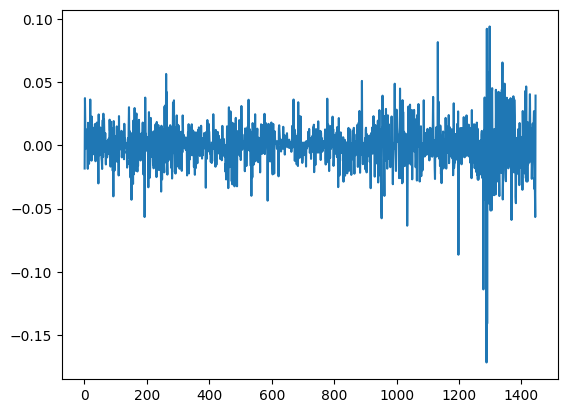

In [50]:
dataset['RL AMBEV'].plot();

In [51]:
dataset['RL AMBEV'].mean()

np.float64(-0.00016235361235990105)

In [52]:
(dataset['RL AMBEV'].mean() * 246) * 100

np.float64(-3.993898864053566)

In [53]:
dataset['RL VIVO'] = np.log(dataset['VIVO'] / dataset['VIVO'].shift(1))
dataset['RL ODONTOPREV'] = np.log(dataset['ODONTOPREV'] / dataset['ODONTOPREV'].shift(1))
dataset['RL PETROBRAS'] = np.log(dataset['PETROBRAS'] / dataset['PETROBRAS'].shift(1))
dataset['RL BBRASIL'] = np.log(dataset['BBRASIL'] / dataset['BBRASIL'].shift(1))
dataset['RL BOVA'] = np.log(dataset['BOVA'] / dataset['BOVA'].shift(1))

In [54]:
dataset.round(2)

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,RS AMBEV,RS VIVO,RS ODONTOPREV,RS PETROBRAS,RS BBRASIL,RS BOVA,RL AMBEV,RL VIVO,RL ODONTOPREV,RL PETROBRAS,RL BBRASIL,RL BOVA
0,2015-01-02,16.02,9.37,37.82,9.00,22.65,47.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-05,15.73,9.62,37.07,8.27,22.18,46.32,-0.02,-0.02,0.03,-0.08,-0.02,-0.02,-0.02,-0.02,0.03,-0.08,-0.02,-0.02
2,2015-01-06,16.33,9.55,36.15,8.06,22.49,46.58,0.04,-0.02,-0.01,-0.03,0.01,0.01,0.04,-0.03,-0.01,-0.03,0.01,0.01
3,2015-01-07,16.56,9.69,37.39,8.45,23.48,48.15,0.01,0.03,0.01,0.05,0.04,0.03,0.01,0.03,0.01,0.05,0.04,0.03
4,2015-01-08,16.54,9.66,38.91,9.02,23.56,48.51,-0.00,0.04,-0.00,0.07,0.00,0.01,-0.00,0.04,-0.00,0.07,0.00,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1441,2020-10-27,13.72,14.00,43.48,19.86,32.78,95.80,-0.03,-0.02,0.03,-0.02,-0.02,-0.01,-0.03,-0.02,0.03,-0.02,-0.02,-0.01
1442,2020-10-28,13.37,12.97,42.61,18.64,31.14,92.43,-0.03,-0.02,-0.07,-0.06,-0.05,-0.04,-0.03,-0.02,-0.08,-0.06,-0.05,-0.04
1443,2020-10-29,12.89,12.84,42.25,19.33,30.96,92.91,-0.04,-0.01,-0.01,0.04,-0.01,0.01,-0.04,-0.01,-0.01,0.04,-0.01,0.01
1444,2020-10-30,12.18,12.61,42.67,19.00,29.80,90.66,-0.06,0.01,-0.02,-0.02,-0.04,-0.02,-0.06,0.01,-0.02,-0.02,-0.04,-0.02


In [55]:
(dataset['RL VIVO'].mean() * 246) * 100

np.float64(2.097939412445287)

In [56]:
(dataset['RL ODONTOPREV'].mean() * 246) * 100

np.float64(4.920259768133881)

In [57]:
(dataset['RL PETROBRAS'].mean() * 246) * 100

np.float64(13.32803046642038)

In [58]:
(dataset['RL BBRASIL'].mean() * 246) * 100

np.float64(4.852406958066642)

In [59]:
(dataset['RL BOVA'].mean() * 246) * 100

np.float64(11.390136891733663)

# Retorno de carteira de ações

In [60]:
dataset = pd.read_csv('acoes_ex.csv')
dataset

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.020000,9.37,37.820000,9.000000,22.650000,47.259998
1,2015-01-05,15.730000,9.62,37.070000,8.270000,22.180000,46.320000
2,2015-01-06,16.330000,9.55,36.150002,8.060000,22.490000,46.580002
3,2015-01-07,16.559999,9.69,37.389999,8.450000,23.480000,48.150002
4,2015-01-08,16.540001,9.66,38.910000,9.020000,23.559999,48.509998
...,...,...,...,...,...,...,...
1441,2020-10-27,13.720000,14.00,43.480000,19.860001,32.779999,95.800003
1442,2020-10-28,13.370000,12.97,42.610001,18.639999,31.139999,92.430000
1443,2020-10-29,12.890000,12.84,42.250000,19.330000,30.959999,92.910004
1444,2020-10-30,12.180000,12.61,42.669998,19.000000,29.799999,90.660004


In [61]:
dataset_normalizado = dataset.copy()
for i in dataset_normalizado.columns[1:]:
  dataset_normalizado[i] = (dataset_normalizado[i] / dataset_normalizado[i][0])

In [62]:
dataset_normalizado

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449
...,...,...,...,...,...,...,...
1441,2020-10-27,0.856429,1.494130,1.149656,2.206667,1.447241,2.027084
1442,2020-10-28,0.834582,1.384205,1.126653,2.071111,1.374834,1.955777
1443,2020-10-29,0.804619,1.370331,1.117134,2.147778,1.366887,1.965933
1444,2020-10-30,0.760300,1.345784,1.128239,2.111111,1.315673,1.918324


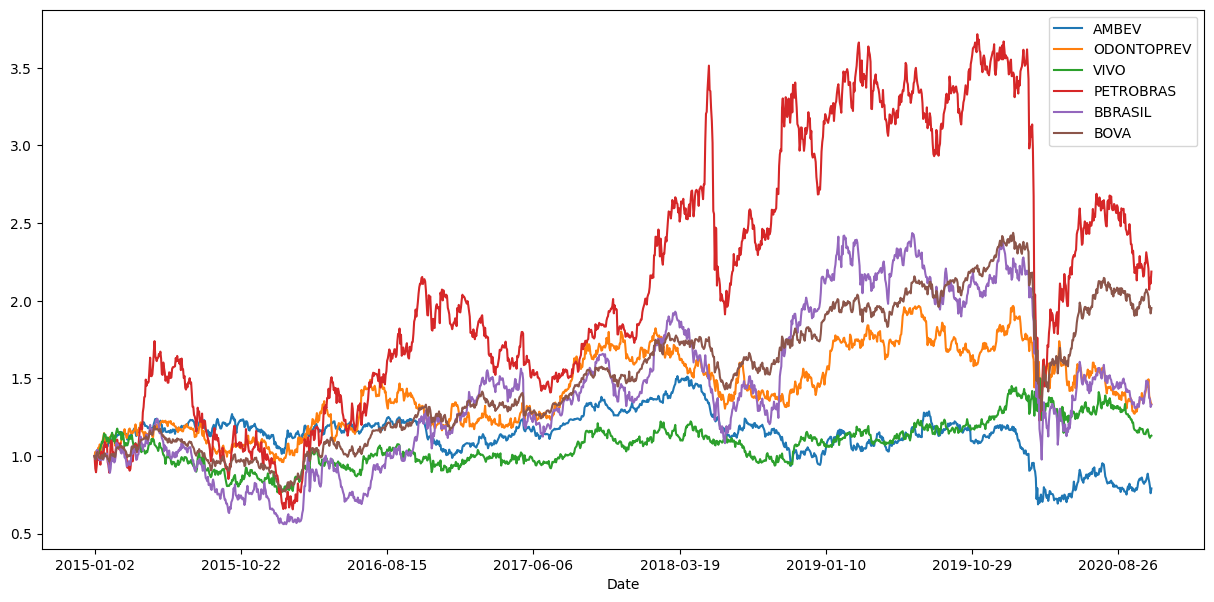

In [63]:
dataset_normalizado.plot(x = 'Date', figsize=(15, 7));

In [64]:
dataset_normalizado.drop(labels=['Date'], axis=1, inplace=True)

In [65]:
retorno_carteira = (dataset_normalizado / dataset_normalizado.shift(1)) - 1
retorno_carteira.head()

,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.018102,0.026681,-0.019831,-0.081111,-0.020751,-0.019890
2,0.038144,-0.007276,-0.024818,-0.025393,0.013977,0.005613
3,0.014084,0.014660,0.034301,0.048387,0.044020,0.033705
4,-0.001208,-0.003096,0.040653,0.067456,0.003407,0.007477


In [66]:
retorno_anual = retorno_carteira.mean() * 246
retorno_anual

,0
AMBEV,-0.003055
ODONTOPREV,0.098360
VIVO,0.071963
PETROBRAS,0.276396
BBRASIL,0.159670
BOVA,0.151077


In [67]:
retorno_anual = retorno_anual * 100
retorno_anual

,0
AMBEV,-0.305458
ODONTOPREV,9.835984
VIVO,7.196278
PETROBRAS,27.639591
BBRASIL,15.967003
BOVA,15.107699


In [68]:
pesos_carteira1 = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0])

In [69]:
pesos_carteira1.sum()

np.float64(1.0)

In [70]:
np.dot(retorno_anual, pesos_carteira1)

np.float64(12.066679602082445)

In [71]:
pesos_carteira2 = np.array([0.1, 0.2, 0.2, 0.4, 0.1, 0.0])

In [72]:
pesos_carteira2.sum()

np.float64(1.0)

In [73]:
np.dot(retorno_anual, pesos_carteira2)

np.float64(16.02844330428113)

## Gráfico da carteira x BOVA

In [74]:
dataset = pd.read_csv('acoes_ex.csv')

In [75]:
dataset['Date'] = pd.to_datetime(dataset['Date'])

In [76]:
dataset_normalizado = dataset.copy()
for i in dataset_normalizado.columns[1:]:
  dataset_normalizado[i] = (dataset_normalizado[i] / dataset_normalizado[i][0])
dataset_normalizado.head()

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449


In [77]:
dataset_normalizado['CARTEIRA'] = (dataset_normalizado['AMBEV'] + dataset_normalizado['ODONTOPREV'] + dataset_normalizado['VIVO'] + dataset_normalizado['PETROBRAS'] + dataset_normalizado['BBRASIL']) / 5
dataset_normalizado

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110,0.977377
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612,0.976579
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832,1.006405
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449,1.026926
...,...,...,...,...,...,...,...,...
1441,2020-10-27,0.856429,1.494130,1.149656,2.206667,1.447241,2.027084,1.430825
1442,2020-10-28,0.834582,1.384205,1.126653,2.071111,1.374834,1.955777,1.358277
1443,2020-10-29,0.804619,1.370331,1.117134,2.147778,1.366887,1.965933,1.361350
1444,2020-10-30,0.760300,1.345784,1.128239,2.111111,1.315673,1.918324,1.332221


In [78]:
figura = px.line(title = 'Comparativo individual + carteira x BOVA')
for i in dataset_normalizado.columns[1:]:
  figura.add_scatter(x = dataset['Date'], y = dataset_normalizado[i], name = i)
figura.show()

In [79]:
dataset_normalizado.drop(['AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL'], axis = 1, inplace= True)
dataset_normalizado

,Date,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000
1,2015-01-05,0.980110,0.977377
2,2015-01-06,0.985612,0.976579
3,2015-01-07,1.018832,1.006405
4,2015-01-08,1.026449,1.026926
...,...,...,...
1441,2020-10-27,2.027084,1.430825
1442,2020-10-28,1.955777,1.358277
1443,2020-10-29,1.965933,1.361350
1444,2020-10-30,1.918324,1.332221


In [80]:
figura = px.line(title = 'Comparativo carteira x BOVA')
for i in dataset_normalizado.columns:
  figura.add_scatter(x = dataset['Date'], y = dataset_normalizado[i], name = i)
figura.show()

## Exercício

### Taxa de retorno da carteira

In [81]:
dataset1 = pd.read_csv('acoes_ex.csv')
dataset1

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,2015-01-02,16.020000,9.37,37.820000,9.000000,22.650000,47.259998
1,2015-01-05,15.730000,9.62,37.070000,8.270000,22.180000,46.320000
2,2015-01-06,16.330000,9.55,36.150002,8.060000,22.490000,46.580002
3,2015-01-07,16.559999,9.69,37.389999,8.450000,23.480000,48.150002
4,2015-01-08,16.540001,9.66,38.910000,9.020000,23.559999,48.509998
...,...,...,...,...,...,...,...
1441,2020-10-27,13.720000,14.00,43.480000,19.860001,32.779999,95.800003
1442,2020-10-28,13.370000,12.97,42.610001,18.639999,31.139999,92.430000
1443,2020-10-29,12.890000,12.84,42.250000,19.330000,30.959999,92.910004
1444,2020-10-30,12.180000,12.61,42.669998,19.000000,29.799999,90.660004


In [82]:
acoes_df_normalizado = dataset1.copy()
for i in acoes_df_normalizado.columns[1:]:
  acoes_df_normalizado[i] = (acoes_df_normalizado[i] / acoes_df_normalizado[i][0])

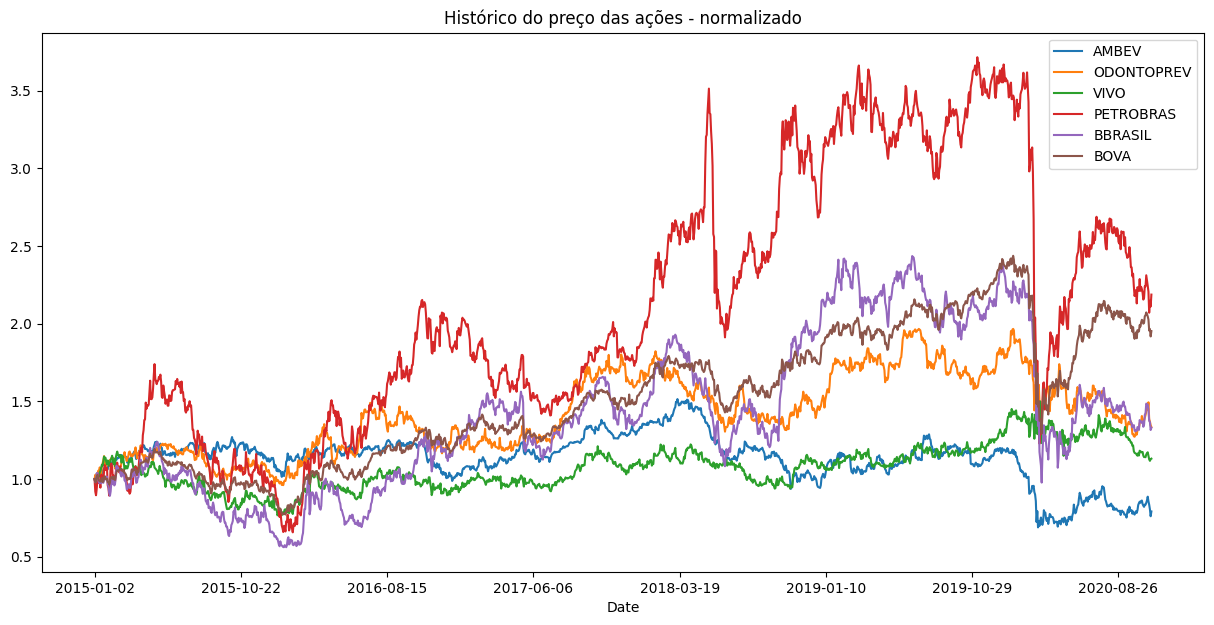

In [83]:
acoes_df_normalizado.plot(x = 'Date', figsize = (15,7), title = 'Histórico do preço das ações - normalizado');

In [84]:
acoes_df_normalizado.drop(labels = ['Date'], axis = 1, inplace = True)

In [85]:
retorno_carteira = (acoes_df_normalizado / acoes_df_normalizado.shift(1)) - 1
retorno_carteira.head()

,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA
0,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.018102,0.026681,-0.019831,-0.081111,-0.020751,-0.019890
2,0.038144,-0.007276,-0.024818,-0.025393,0.013977,0.005613
3,0.014084,0.014660,0.034301,0.048387,0.044020,0.033705
4,-0.001208,-0.003096,0.040653,0.067456,0.003407,0.007477


In [86]:
retorno_anual = retorno_carteira.mean() * 246
retorno_anual

,0
AMBEV,-0.003055
ODONTOPREV,0.098360
VIVO,0.071963
PETROBRAS,0.276396
BBRASIL,0.159670
BOVA,0.151077


In [87]:
retorno_anual = retorno_anual * 100
retorno_anual

,0
AMBEV,-0.305458
ODONTOPREV,9.835984
VIVO,7.196278
PETROBRAS,27.639591
BBRASIL,15.967003
BOVA,15.107699


In [88]:
pesos_carteira = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0])

In [89]:
np.dot(retorno_anual, pesos_carteira)

np.float64(12.066679602082445)

### Gráfico carteira x BOVA

In [90]:
dataset1 = pd.read_csv('acoes_ex.csv')

In [91]:
acoes_df_normalizado = dataset1.copy()
for i in acoes_df_normalizado.columns[1:]:
  acoes_df_normalizado[i] = (acoes_df_normalizado[i] / acoes_df_normalizado[i][0])

In [92]:
dataset1.columns

Index(['Date', 'AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL', 'BOVA'], dtype='object')

In [93]:
acoes_df_normalizado['CARTEIRA'] = (acoes_df_normalizado['AMBEV'] + acoes_df_normalizado['ODONTOPREV'] + acoes_df_normalizado['VIVO'] + acoes_df_normalizado['PETROBRAS'] + acoes_df_normalizado['BBRASIL']) / 5
acoes_df_normalizado

,Date,AMBEV,ODONTOPREV,VIVO,PETROBRAS,BBRASIL,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2015-01-05,0.981898,1.026681,0.980169,0.918889,0.979249,0.980110,0.977377
2,2015-01-06,1.019351,1.019210,0.955844,0.895556,0.992936,0.985612,0.976579
3,2015-01-07,1.033708,1.034152,0.988630,0.938889,1.036645,1.018832,1.006405
4,2015-01-08,1.032459,1.030950,1.028821,1.002222,1.040177,1.026449,1.026926
...,...,...,...,...,...,...,...,...
1441,2020-10-27,0.856429,1.494130,1.149656,2.206667,1.447241,2.027084,1.430825
1442,2020-10-28,0.834582,1.384205,1.126653,2.071111,1.374834,1.955777,1.358277
1443,2020-10-29,0.804619,1.370331,1.117134,2.147778,1.366887,1.965933,1.361350
1444,2020-10-30,0.760300,1.345784,1.128239,2.111111,1.315673,1.918324,1.332221


In [94]:
figura = px.line(title = 'Histórico do preço das ações')
for i in acoes_df_normalizado.columns[1:]:
  figura.add_scatter(x = acoes_df_normalizado['Date'], y = acoes_df_normalizado[i], name = i)
figura.show()

In [95]:
acoes_df_normalizado.drop(['AMBEV', 'ODONTOPREV', 'VIVO', 'PETROBRAS', 'BBRASIL'], axis = 1, inplace = True)
acoes_df_normalizado

,Date,BOVA,CARTEIRA
0,2015-01-02,1.000000,1.000000
1,2015-01-05,0.980110,0.977377
2,2015-01-06,0.985612,0.976579
3,2015-01-07,1.018832,1.006405
4,2015-01-08,1.026449,1.026926
...,...,...,...
1441,2020-10-27,2.027084,1.430825
1442,2020-10-28,1.955777,1.358277
1443,2020-10-29,1.965933,1.361350
1444,2020-10-30,1.918324,1.332221


In [96]:
figura = px.line(title = 'Histórico do preço das ações')
for i in acoes_df_normalizado.columns[1:]:
  figura.add_scatter(x = acoes_df_normalizado['Date'], y = acoes_df_normalizado[i], name = i)
figura.show()

In [97]:
# Filtrando as colunas que contêm o retorno logarítmico (RL)
colunas_rl = [col for col in dataset.columns if col.startswith('RL')]

print("--- Médias dos Retornos Logarítmicos (RL) ---\n")
for col in colunas_rl:
    media_diaria = dataset[col].mean()
    media_anualizada = media_diaria * 246 * 100
    print(f"{col}:")
    print(f"  Média Diária: {media_diaria:.6f}")
    print(f"  Média Anualizada: {media_anualizada:.2f}%\n")

--- Médias dos Retornos Logarítmicos (RL) ---

